# Assignment 2(due on 10/28)

## Student: 苗子凡（12632733），Github: AndrewFancyMIAO

## 批改人：张鹏

## 得分：94/100 

In [2]:
##### PS_1
### 1.1
# 加载pandas和plot
import pandas as pd
import matplotlib.pyplot as plt

# 读取文件
Sig_Eqs = pd.read_csv("/home/zhangp/桌面/A2/earthquakes-2026-10-30_17-09-02_+0800.tsv",delimiter='\t').fillna(0)  # 助教更改读取路径

# 将数据中数值的空值替换为0
num_cols = Sig_Eqs.select_dtypes(include='number').columns
Sig_Eqs[num_cols] = Sig_Eqs[num_cols].fillna(0)

# 统计死亡人数
Deaths_Country = Sig_Eqs.groupby('Country')['Total Deaths'].sum().reset_index().sort_values(by='Total Deaths',ascending=False).reset_index(drop=True)
print(Deaths_Country.head(20))

         Country  Total Deaths
0          CHINA     2106542.0
1         TURKEY     1008867.0
2           IRAN      761641.0
3          ITALY      417297.0
4          SYRIA      358326.0
5          HAITI      323782.0
6          JAPAN      319510.0
7     AZERBAIJAN      319251.0
8      INDONESIA      283485.0
9        ARMENIA      175000.0
10      PAKISTAN      143714.0
11       ECUADOR      134445.0
12  TURKMENISTAN      110412.0
13          PERU       97009.0
14        GREECE       83658.0
15      PORTUGAL       82572.0
16          IRAQ       70200.0
17         CHILE       70175.0
18         INDIA       63413.0
19        ISRAEL       58368.0


findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.


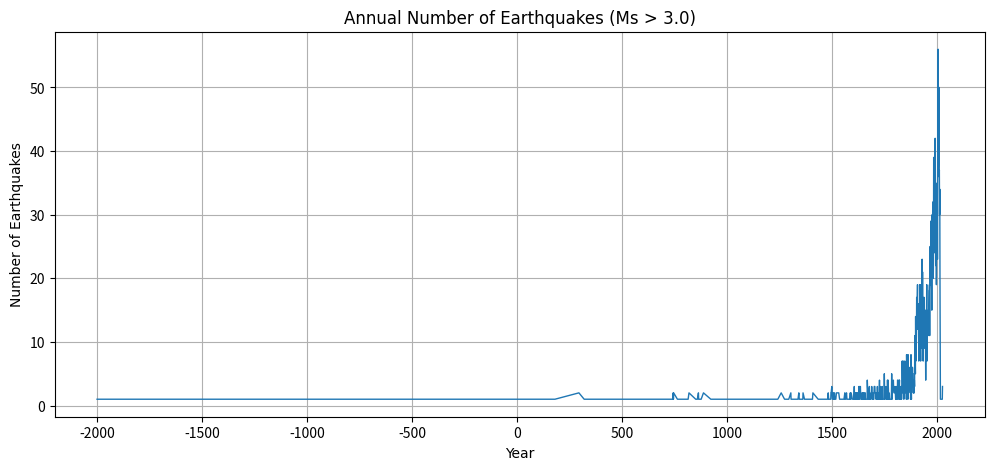

<Figure size 640x480 with 0 Axes>

In [3]:
### 1.2
# 筛选Ms > 3.0的时间
Ms_3 = Sig_Eqs.loc[(Sig_Eqs['Ms'] > 3.0)].reset_index(drop=True)

# 按年份统计次数
Ms_Year = Ms_3.groupby('Year').size()

# 绘图
plt.figure(figsize=(12,5))
plt.plot(Ms_Year,linewidth=1)
plt.xlabel('Year',fontname = 'Times New Roman')
plt.ylabel('Number of Earthquakes',fontname = 'Times New Roman')
plt.title('Annual Number of Earthquakes (Ms > 3.0)',fontname = 'Times New Roman')
plt.grid(True)
plt.show()

# 保存图片
plt.savefig(r"..\ESE5023\PS2_1_2.png",
            dpi = 300,
            bbox_inches="tight")

In [4]:
### 1.3
# 定义函数CountEq_LargestEq()
def CountEq_LargestEq(country):
    # 读取输入的国家名称
    country_eq = Sig_Eqs[Sig_Eqs['Country'] == country]
    # 统计地震数量、date和location
    N = len(country_eq)
    ID = country_eq.loc[country_eq['Ms'].idxmax()]
    YY = int(ID['Year'])
    MM = int(ID['Mo'])
    DD = int(ID['Dy'])
    Loc = ID['Location Name']
    Lat = float(ID['Latitude'])
    Lon = float(ID['Longitude'])
    return N,YY,MM,DD,Loc,Lat,Lon

# 创建国家列表，排除NaN值和重复值
countries = Sig_Eqs['Country'].dropna().unique()

# 实际应用时发现有一国家名称为0，故舍去
countries = Sig_Eqs.loc[Sig_Eqs['Country'].notna()&(Sig_Eqs['Country'].astype(str) != '0'),'Country'].unique()

# 创建空列表以便储存结果
Res = []

# 循环读取各个国家的数据
for country in countries:
    res = CountEq_LargestEq(country)
    Res.append((country,*res))
    # 打印结果
    print(country,' has recorded a total number of ',res[0],'earthquakes since 2150 B.C. The largest event in the dataset occurred on ',res[2],'/',res[3],'/',res[1],'. \nThe affected area is listed as ',res[4],', with coordinates of ',res[5],'° lagitude and ',res[6],'° longitude.',sep='')

# 新建表头
columns = ['Country','N','YY','MM','DD','Loc','Lat','Lon',]
RES = pd.DataFrame(Res, columns=columns).sort_values(by='N',ascending=False).reset_index()
print(RES)

JORDAN has recorded a total number of 5earthquakes since 2150 B.C. The largest event in the dataset occurred on 5/24/362. 
The affected area is listed as JORDAN:  AL-KARAK, with coordinates of 31.3° lagitude and 35.6° longitude.
SYRIA has recorded a total number of 33earthquakes since 2150 B.C. The largest event in the dataset occurred on 5/20/1202. 
The affected area is listed as SYRIA:  SOUTHWESTERN, with coordinates of 33.5° lagitude and 36.0° longitude.
TURKMENISTAN has recorded a total number of 12earthquakes since 2150 B.C. The largest event in the dataset occurred on 7/8/1895. 
The affected area is listed as TURKMENISTAN:  UZUN-ADA, with coordinates of 39.5° lagitude and 53.7° longitude.
GREECE has recorded a total number of 296earthquakes since 2150 B.C. The largest event in the dataset occurred on 7/21/365. 
The affected area is listed as GREECE:  CRETE:  KNOSSOS, with coordinates of 35.0° lagitude and 23.0° longitude.
ISRAEL has recorded a total number of 25earthquakes since 

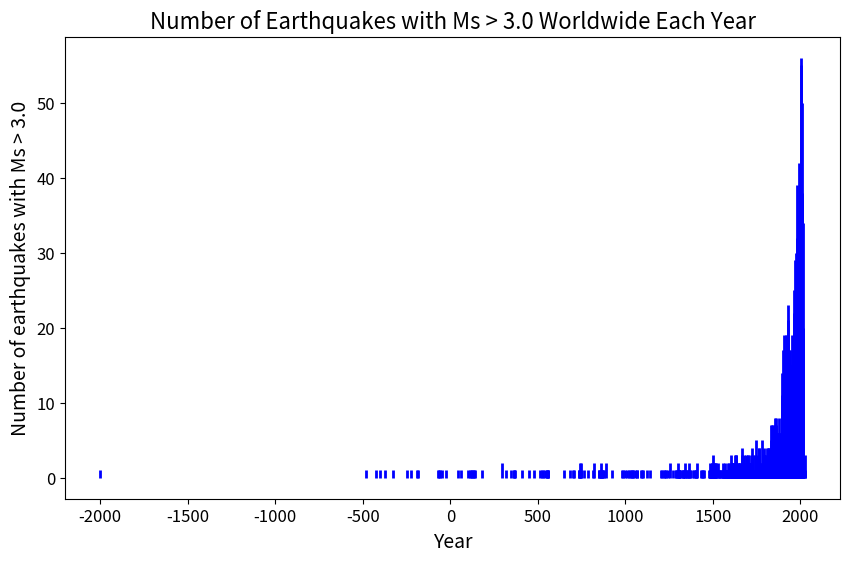

In [5]:
#1.2 助教添加
# 筛选出震级大于6.0的地震
large_quakes = Sig_Eqs[Sig_Eqs['Ms'] > 3.0]

# 按年份对数据进行分组，并得到每年的地震次数
quakes_by_year = large_quakes.groupby('Year')['Ms'].count()

plt.figure(figsize=(10, 6))
plt.vlines(quakes_by_year.index, ymin=0, ymax=quakes_by_year.values, color='blue', linewidth=2)
plt.xlabel('Year', fontsize=14)
plt.ylabel('Number of earthquakes with Ms > 3.0', fontsize=14)
plt.title('Number of Earthquakes with Ms > 3.0 Worldwide Each Year', fontsize=16)
plt.tick_params(axis='both', which='major', labelsize=12)

# Displaying the plot
plt.show()

### 第一题代码运行正常，可以输出正确结果，报告中也展示了输出内容，也针对问题给出文字分析。第二问绘图有一点点问题，没有数据的年份不应该有数据，建议绘制竖线图或者删除NAN值后绘图，见上面代码助教添加代码


### 得分：23/25
### --------------------------------------------------------------------------------------------

findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.


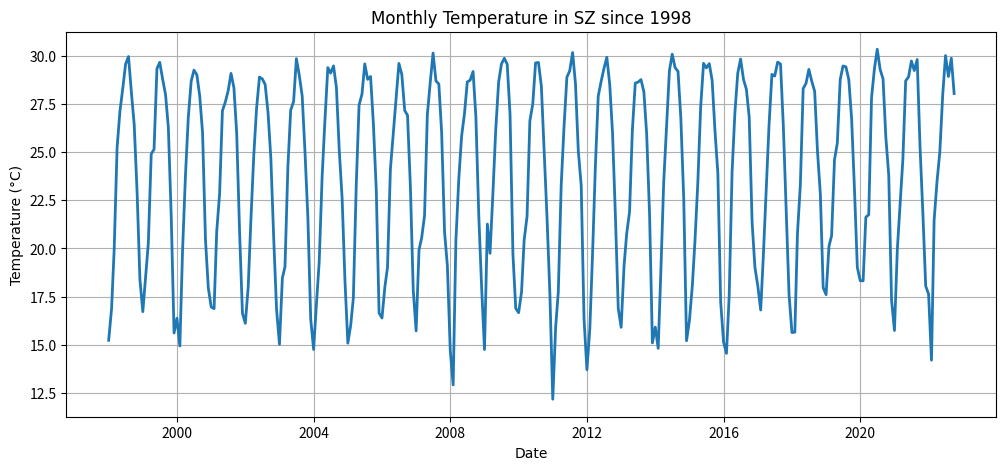

<Figure size 640x480 with 0 Axes>

In [6]:
##### PS_2
# 加载pandas和plot
import pandas as pd
import matplotlib.pyplot as plt

# 读取文件
data = pd.read_csv("/home/zhangp/桌面/A2/Baoan_Weather_1998_2022.csv",low_memory=False)  # 助教更改读取路径

# 转换日期格式
data['DATE'] = pd.to_datetime(data['DATE'])

# 命名表头
column = ['value', 'code']

# 拆分文件中的value和code再合并时间和表头
TMP = data['TMP'].str.split(',', expand=True)
TMP.columns = column
TMP.insert(0, 'DATE', data['DATE'])

# 将数据从str转换为float
TMP['value'] = pd.to_numeric(TMP['value'], errors='coerce')

# 筛选数据
TMP_true = TMP.loc[((TMP['code'] == '1') | (TMP['code'] == '5') | (TMP['code'] == '2') | (TMP['code'] == '4'))].reset_index(drop=True)
TMP_true = TMP_true.loc[((TMP_true['value'] > -932) & (TMP_true['value'] < 618))].reset_index(drop=True)

# 计算真值和逐月平均值
TMP_true['value'] = TMP_true['value'] / 10
TMP_mean = TMP_true.groupby(TMP_true['DATE'].dt.to_period('M'))['value'].mean()

# 绘图
plt.figure(figsize=(12, 5))
plt.plot(TMP_mean.index.to_timestamp(),TMP_mean.values,linewidth=2)
plt.xlabel('Date',fontname='Times New Roman')
plt.ylabel('Temperature (°C)',fontname='Times New Roman')
plt.title('Monthly Temperature in SZ since 1998',fontname='Times New Roman')
plt.grid(True)
plt.show()

# 保存图片
plt.savefig(r"..\ESE5023\PS2_1_2.png",
            dpi = 300,
            bbox_inches="tight")

### 代码运行正确且有相应分析，以及guide中的数据筛选，后续建议采用拟合方法进行趋势分析


### 得分：10/10
### --------------------------------------------------------------------------------------------

In [9]:
##### PS_3
# 加载pandas和plot
import pandas as pd
import matplotlib.pyplot as plt

### 3.1
# 读取文件
data3 = pd.read_csv("/home/zhangp/桌面/A2/ibtracs.ALL.list.v04r00.csv",low_memory=False,usecols=range(17),skiprows=[1, 2],parse_dates=['ISO_TIME'],na_values=['NOT_NAMED', 'NAME'])  # 助教更改读取路径
# 按SID分组并提取每个SID最大的风速
data3_1 = data3.groupby('SID').agg({'NAME': 'first', 'WMO_WIND': 'max'}).reset_index()

# 剔除NaN值
data3_1 = data3_1.loc[data3_1['NAME'].notna()]

# 按大小排序
data3_1 = data3_1.sort_values(by='WMO_WIND', ascending=False).head(10).reset_index(drop=True)
print(data3_1['NAME'].to_string(index=False))

 NELSON
FRANCES
  BELLE
ANNETTE
 GUSTAV
    IKE
SINLAKU
 JANGMI
NORBERT
   OMAR


In [10]:
#助教添加
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_csv(
    "/home/zhangp/桌面/A2/ibtracs.ALL.list.v04r00.csv",  # 助教更改读取路径
    usecols=range(17),
    skiprows=[1],
    parse_dates=["ISO_TIME"],
    keep_default_na=False,
    na_values=[" ", "NOT_NAMED"],
    low_memory=False,
)
storms = (
    df.groupby("SID")
    .agg(NAME=("NAME", "first"), WMO_WIND=("WMO_WIND", "max"))
)

largest_10 = storms.sort_values("WMO_WIND", ascending=False).head(10)
largest_10[["NAME"]]

,NAME
SID,
2015293N13266,PATRICIA
1980214N11330,ALLEN
2019236N10314,DORIAN
1988253N12306,GILBERT
2005289N18282,WILMA
1935241N23291,None
1997253N12255,LINDA
2017242N16333,IRMA
1998295N12284,MITCH


### 按 SID 分组思路正确，但 WMO_WIND 未转为数值，导致最大值和排序结果错误；应按风速有效性筛选，而非删除无名气旋。-1
### --------------------------------------------------------------------------------------------

In [8]:
### 3.2
# 按风速排序
data3_2 = data3.sort_values(by='WMO_WIND',ascending=False).head(20).reset_index(drop=True)

# 输出结果
for i in range(20): 
    print(i+1,'. ',data3_2['WMO_WIND'][i],'m/s',sep='')

1. 95m/s
2. 95m/s
3. 95m/s
4. 95m/s
5. 95m/s
6. 95m/s
7. 95m/s
8. 95m/s
9. 95m/s
10. 95m/s
11. 95m/s
12. 95m/s
13. 95m/s
14. 95m/s
15. 95m/s
16. 95m/s
17. 95m/s
18. 95m/s
19. 95m/s
20. 95m/s


In [11]:
#助教添加
strongest_20 = storms.sort_values("WMO_WIND", ascending=False).head(20)
strongest_20[["NAME", "WMO_WIND"]]

,NAME,WMO_WIND
SID,,
2015293N13266,PATRICIA,185.0
1980214N11330,ALLEN,165.0
2019236N10314,DORIAN,160.0
1988253N12306,GILBERT,160.0
2005289N18282,WILMA,160.0
1935241N23291,None,160.0
1997253N12255,LINDA,160.0
2017242N16333,IRMA,155.0
1998295N12284,MITCH,155.0


### 未按 SID 汇总各气旋的最大风速，存在同一气旋重复计入的问题。-1
### --------------------------------------------------------------------------------------------

In [14]:
### 3.3
print(data3.groupby(data3['BASIN']).size())

BASIN
EP     62412
NI     55401
SA       119
SI    160668
SP     67119
WP    236576
dtype: int64


In [13]:
#助教添加
basin_counts = df.groupby("BASIN").size().sort_values(ascending=False)
basin_counts

BASIN
WP    236576
SI    160668
NA    124881
SP     67119
EP     62412
NI     55402
SA       119
dtype: int64

### pandas会把NA默认为NAN因此缺少统计NA Basin的量-2
### --------------------------------------------------------------------------------------------

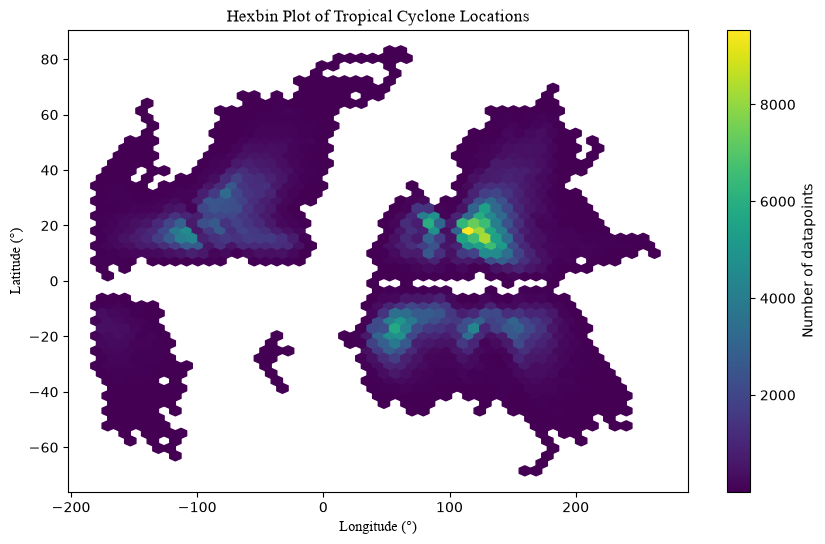

<Figure size 640x480 with 0 Axes>

In [96]:
### 3.4
# 读取经纬度并舍弃NaN值
data3_4 = data3.dropna(subset=['LAT', 'LON'])

# 绘图
plt.figure(figsize=(10, 6))
plt.hexbin(data3_4['LON'],data3_4['LAT'],gridsize=50,mincnt=1)
plt.colorbar(label='Number of datapoints')
plt.xlabel('Longitude (°)',fontname='Times New Roman')
plt.ylabel('Latitude (°)',fontname='Times New Roman')
plt.title('Hexbin Plot of Tropical Cyclone Locations',fontname='Times New Roman')
plt.show()

# 保存图片
plt.savefig(r"..\ESE5023\PS2_3_4.png",
            dpi = 300,
            bbox_inches="tight")

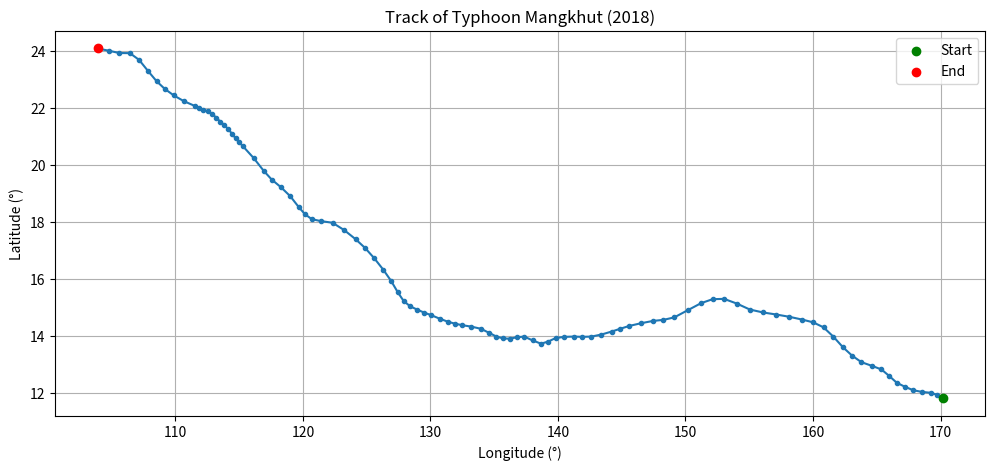

<Figure size 640x480 with 0 Axes>

In [15]:
### 3.5
# 获取2018年MANGKHUB数据
MANGKHUT = data3.loc[(data3['SEASON'] == 2018) &(data3['NAME'] == 'MANGKHUT')]

# 读取SID
sid = MANGKHUT['SID'].iloc[0]

# 提取该 SID 的所有记录
mangkhut = data3.loc[data3['SID'] == sid].copy()

# 剔除NaN值
mangkhut = mangkhut.dropna(subset=['LAT', 'LON'])

# 按时间排序
mangkhut = mangkhut.sort_values(by='ISO_TIME')

# 绘图
plt.figure(figsize=(12, 5))
plt.plot(mangkhut['LON'],mangkhut['LAT'],marker='o',markersize=3,linewidth=1.5)
plt.xlabel('Longitude (°)')
plt.ylabel('Latitude (°)')
plt.title('Track of Typhoon Mangkhut (2018)')
# 标记start & end位置
plt.scatter(mangkhut['LON'].iloc[0],mangkhut['LAT'].iloc[0],color='green',label='Start',zorder=3)
plt.scatter(mangkhut['LON'].iloc[-1], mangkhut['LAT'].iloc[-1],color='red',label='End',zorder=3)
plt.legend()
plt.grid(True)
plt.show()

# 保存图片
plt.savefig(r"..\ESE5023\PS2_3_5.png",
            dpi = 300,
            bbox_inches="tight")

In [16]:
### 3.6
# 筛选1970年及之后的WP和EP的数据
data3_filtered = data3.loc[(data3['SEASON'] >= 1970) & ((data3['BASIN'] == 'EP') | (data3['BASIN'] == 'WP')) ].copy().reset_index(drop=True)

findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.


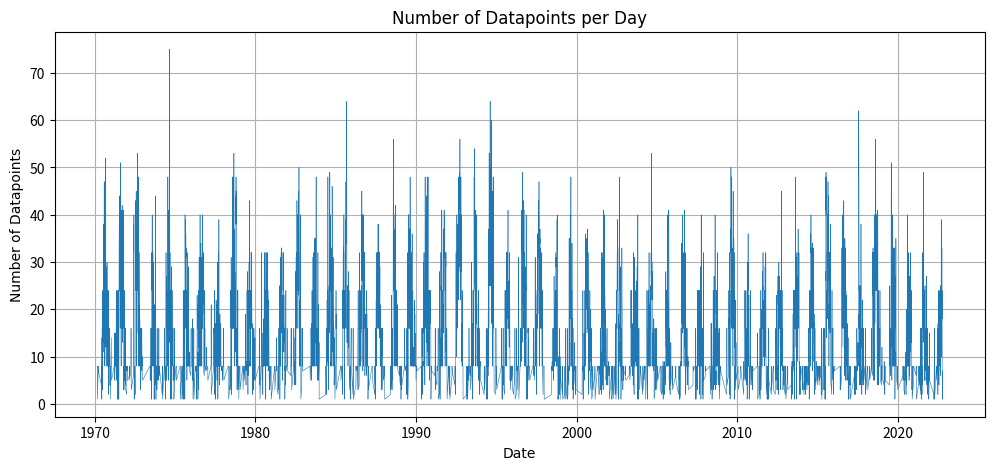

<Figure size 640x480 with 0 Axes>

In [17]:
### 3.7
# 提取日期
data3_filtered['DATE'] = data3_filtered['ISO_TIME'].dt.normalize()

# 统计点数
daily_n = data3_filtered.groupby('DATE').size()

# 绘图
plt.figure(figsize=(12, 5))
plt.plot(daily_n.index,daily_n.values,linewidth=0.4)
plt.xlabel('Date',fontname='Times New Roman')
plt.ylabel('Number of Datapoints',fontname='Times New Roman')
plt.title('Number of Datapoints per Day',fontname='Times New Roman')
plt.grid(True)
plt.show()

# 保存图片
plt.savefig(r"..\ESE5023\PS2_3_7.png",
            dpi = 300,
            bbox_inches="tight")

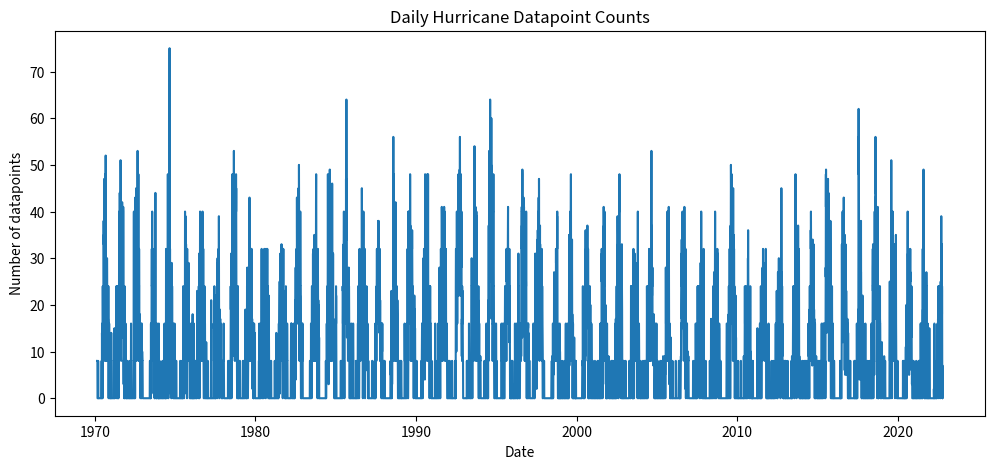

In [22]:
#助教添加
daily_counts = (
    data3_filtered.set_index("ISO_TIME")
    .resample("D")
    .size()
    .rename("count")
)

plt.figure(figsize=(12, 5))
plt.plot(daily_counts.index, daily_counts.values)
plt.xlabel("Date")
plt.ylabel("Number of datapoints")
plt.title("Daily Hurricane Datapoint Counts")
plt.show()

### 代码可以运行但是有观测日期的计数正确但遗漏零计数日期，应该.resample('D').size()建立连续的每日序列，并统计每天的数据点数-1
### --------------------------------------------------------------------------------------------

findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.


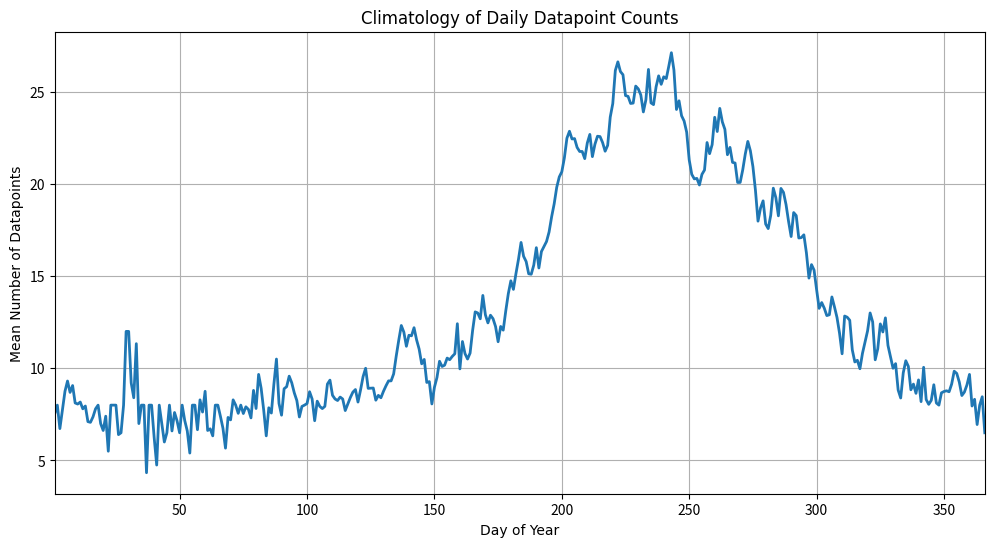

<Figure size 640x480 with 0 Axes>

In [18]:
### 3.8
# 重命名表头
daily_n_DoY = daily_n.rename('COUNT').reset_index()

# 使用dayofyear函数
daily_n_DoY['DAY_OF_YEAR'] = daily_n_DoY['DATE'].dt.dayofyear

# 计算平均值
climatology = daily_n_DoY.groupby('DAY_OF_YEAR')['COUNT'].mean()

# 绘图
plt.figure(figsize=(12, 6))
plt.plot(climatology.index,climatology.values,linewidth=2)
plt.xlabel('Day of Year',fontname='Times New Roman')
plt.ylabel('Mean Number of Datapoints',fontname='Times New Roman')
plt.title('Climatology of Daily Datapoint Counts',fontname='Times New Roman')
plt.xlim(1, 366)
plt.grid(True)
plt.show()

# 保存图片
plt.savefig(r"..\ESE5023\PS2_3_8.png",
            dpi = 300,
            bbox_inches="tight")

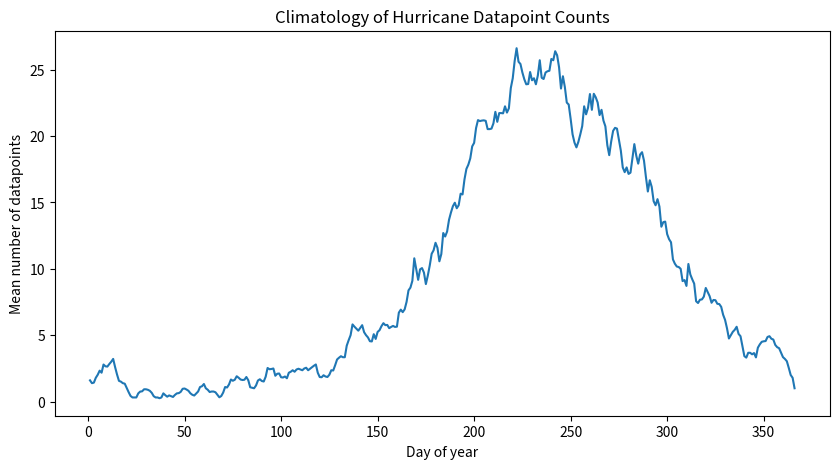

In [23]:
#助教添加
daily = daily_counts.to_frame()
daily["day_of_year"] = daily.index.dayofyear
climatology = daily.groupby("day_of_year")["count"].mean()

plt.figure(figsize=(10, 5))
plt.plot(climatology.index, climatology.values)
plt.xlabel("Day of year")
plt.ylabel("Mean number of datapoints")
plt.title("Climatology of Hurricane Datapoint Counts")
plt.show()

### 代码可以运行只对有观测的年份求平均，气候态偏大-1
### --------------------------------------------------------------------------------------------

In [19]:
### 3.9
# 匹配数据
daily_n_DoY['CLIMATOLOGY'] = daily_n_DoY['DAY_OF_YEAR'].map(climatology)

# 计算异常值
daily_n_DoY['ANOMALY'] = (daily_n_DoY['COUNT'] - daily_n_DoY['CLIMATOLOGY'])

# 输出结果
print(daily_n_DoY['ANOMALY'])

0         1.500000
1         0.000000
2         0.833333
3         1.400000
4         2.600000
           ...    
10812    -8.980769
10813   -11.693878
10814   -17.301887
10815   -12.769231
10816   -15.269231
Name: ANOMALY, Length: 10817, dtype: float64


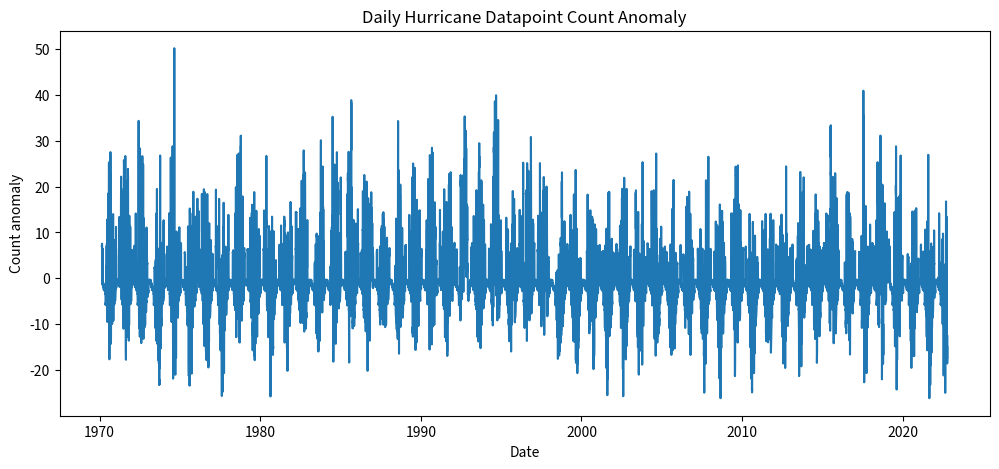

In [24]:
#助教添加
daily["climatology"] = daily["day_of_year"].map(climatology)
daily["anomaly"] = daily["count"] - daily["climatology"]

plt.figure(figsize=(12, 5))
plt.plot(daily.index, daily["anomaly"])
plt.xlabel("Date")
plt.ylabel("Count anomaly")
plt.title("Daily Hurricane Datapoint Count Anomaly")
plt.show()

### 减法公式和索引对齐正确，沿用了上题错误
### --------------------------------------------------------------------------------------------

findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.


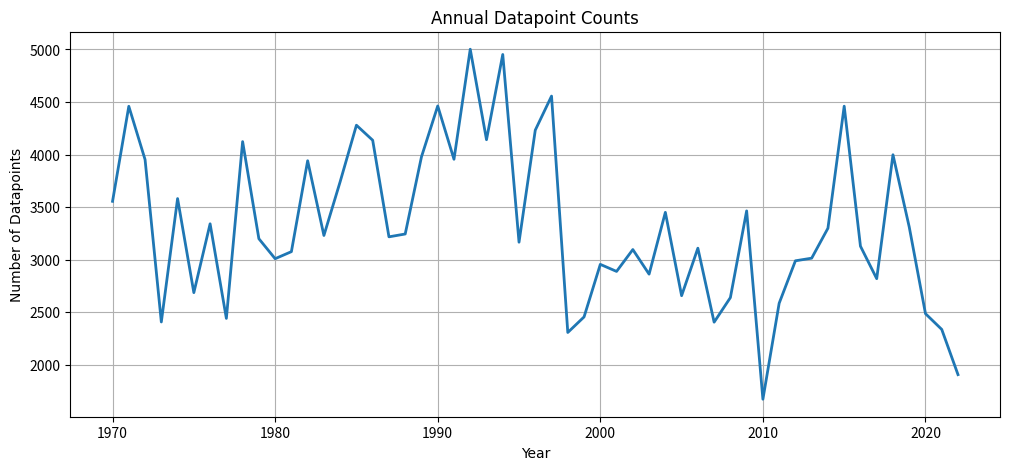

<Figure size 640x480 with 0 Axes>

In [20]:
### 3.10
# 按年分组
daily_n_DoY['YEAR'] = daily_n_DoY['DATE'].dt.year

# 统计数据点年总数
annual_n = daily_n_DoY.groupby('YEAR')['COUNT'].sum().reset_index()

# 绘图
plt.figure(figsize=(12,5))
plt.plot(annual_n.YEAR,annual_n.COUNT,linewidth=2)
plt.xlabel('Year',fontname='Times New Roman')
plt.ylabel('Number of Datapoints',fontname='Times New Roman')
plt.title('Annual Datapoint Counts',fontname='Times New Roman')
plt.grid(True)
plt.show()

# 保存图片
plt.savefig(r"..\ESE5023\PS2_3_10.png",
            dpi = 300,
            bbox_inches="tight")

### 代码思路基本正确一些细节需要注意
### 得分：44/50
### --------------------------------------------------------------------------------------------

In [157]:
##### PS_4
### 4.1
# 加载pandas、numpy、plot和m'da'te's
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 读取数据
data4 = pd.read_csv(r'..\ESE5023\shenzhen-air-quality.csv')

# 将空白值替换为NaN
data4 = data4.replace(r'^\s*$', np.nan, regex=True)

# 转换时间序列
data4['date'] = pd.to_datetime(data4['date'], format='%Y/%m/%d')
data4 = data4.sort_values(by='date')

# 删除所有列名前后的空格
data4.columns = data4.columns.str.strip()

# 需要转换为数值类型的列名
cols = ['pm25', 'pm10', 'co', 'so2', 'o3', 'no2']

# 将这六列全部转换为数值类型
data4[cols] = data4[cols].apply(pd.to_numeric, errors='coerce')

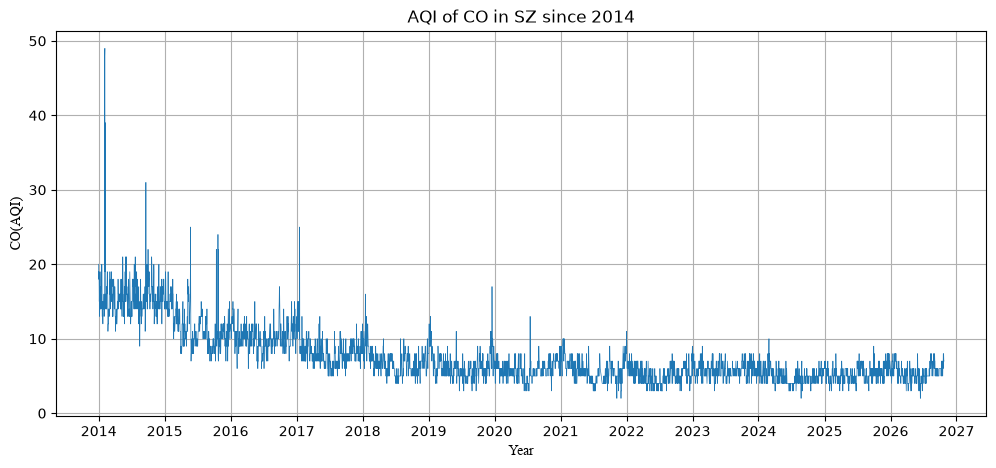

<Figure size 640x480 with 0 Axes>

In [158]:
### 4.2
# 删除co中的缺失值
data4 = data4.dropna(subset=['co'])

# 绘图
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(data4['date'], data4['co'], linewidth=0.5)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.set_xlabel('Year', fontname='Times New Roman')
ax.set_ylabel('CO(AQI)', fontname='Times New Roman')
ax.set_title('AQI of CO in SZ since 2014')
ax.grid(True)
plt.show()

# 保存图片
plt.savefig(r"..\ESE5023\PS2_4_2.png",
            dpi = 300,
            bbox_inches="tight")

count    4650.000000
mean        7.479785
std         3.618403
min         2.000000
25%         5.000000
50%         6.000000
75%         9.000000
max        49.000000
Name: co, dtype: float64
Median: 6.0
Skewness: 2.089452543038353


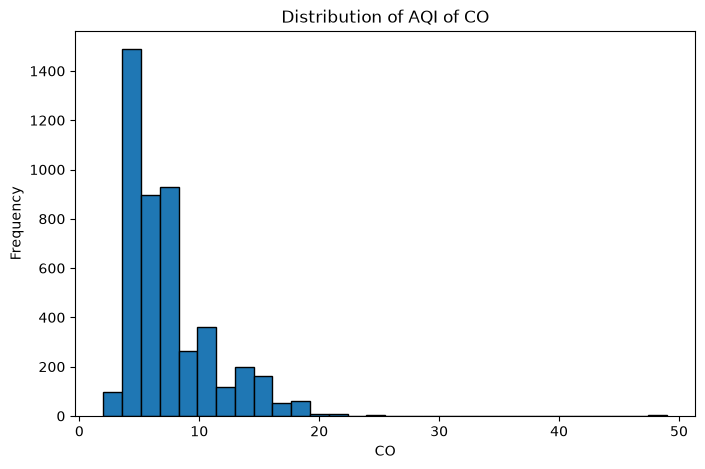

Lower bound: -1.0
Upper bound: 15.0
Potential outliers: 209
Outlier percentage: 4.494623655913978 %
date
2013    20.000000
2014    15.781768
2015    11.530220
2016    10.170799
2017     8.166205
2018     6.788462
2019     6.209366
2020     5.818681
2021     5.721127
2022     5.200000
2023     5.778082
2024     4.901099
2025     5.317680
2026     5.457912
Name: co, dtype: float64


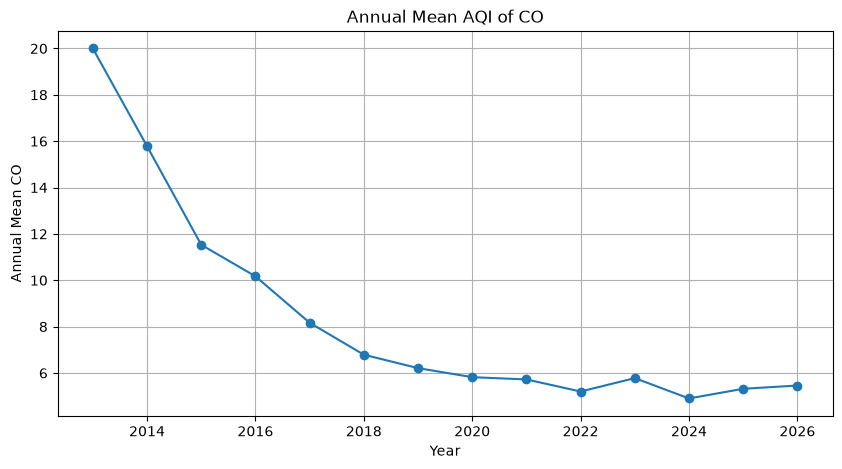

<Figure size 640x480 with 0 Axes>

In [161]:
### 4.3
co = data4['co']

# 1.描述性统计量
print(co.describe())
print('Median:', co.median())

# 2.偏度
print('Skewness:', co.skew())

# 3.分布形态
plt.figure(figsize=(8, 5))
plt.hist(co, bins=30, edgecolor='black')
plt.xlabel('CO')
plt.ylabel('Frequency')
plt.title('Distribution of AQI of CO')
plt.show()

# 保存图片
plt.savefig(r"..\ESE5023\PS2_4_3_3.png",
            dpi = 300,
            bbox_inches="tight")

# 4.异常值
Q1 = co.quantile(0.25)
Q3 = co.quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
outliers = co[(co < lower) | (co > upper)]
print('Lower bound:', lower)
print('Upper bound:', upper)
print('Potential outliers:', len(outliers))
print('Outlier percentage:', len(outliers) / len(co) * 100, '%')

# 5.年际变化
annual_co = data4.groupby(data4['date'].dt.year)['co'].mean()
print(annual_co)
annual_co.plot(figsize=(10, 5), marker='o')
plt.xlabel('Year')
plt.ylabel('Annual Mean CO')
plt.title('Annual Mean AQI of CO')
plt.grid(True)
plt.show()

# 保存图片
plt.savefig(r"..\ESE5023\PS2_4_3_5.png",
            dpi = 300,
            bbox_inches="tight")

### 代码结果展示正确且有相应分析最后统计有相应图片


### 得分：16/15
### --------------------------------------------------------------------------------------------
### 建议后续作业可以在文件夹中放入原始数据方便助教运行并检查代码
### 报告英文且解释详细+1